# Part 3 — Machine Learning: predict no-shows and choose the model honestly

## Task 3.1 — Features, split and baseline

Build X from age, distance_km, fee_inr, lead_days, prior_no_shows, reminder_sent (convert Yes/No to 1/0 with .map), and the one-hot encoded booking_channel and visit_type (pd.get_dummies(X, columns=["booking_channel","visit_type"])). Do not use patient_id, appointment_id, dates, clinic_id, gender or status as features. Target y = no_show. Split with train_test_split(X, y, test_size=0.2, random_state=42). Report the training and test sizes, the number of no-shows in the test set, and the baseline accuracy of always predicting "Attended". Do not shuffle or re-sort the rows after loading appointments_clean.csv: the exact test-set counts below depend on the row order of that file.

In [ ]:
import pandas as pd
import warnings
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

warnings.filterwarnings('ignore')

# Read the cleaned data of appointments
appts_clean_df = pd.read_csv('/content/appointments_clean.csv')

data = appts_clean_df[['age','distance_km','fee_inr','lead_days','prior_no_shows','reminder_sent','booking_channel','visit_type']]

# Convert the Yes/No into 1/0
data['reminder_sent_flag'] = (data['reminder_sent'] == 'Yes').astype(int)

# Drop the duplicate column
data = data.drop(columns='reminder_sent')

# One-Hot encoding of non-numerical values
X = pd.get_dummies(data, drop_first=True ,dtype=int)

# Target
y = appts_clean_df['no_show']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Report the training and test sizes
print(f'Training data size: {X_train.shape[0]}')
print(f'Testing data size: {X_test.shape[0]}')

# Number of no shows in the test set
print(f'Number of no_shows in the test set: {y_test.sum()}')


# Predicting always as attended
pred_always_attended = 0

# Create a baseline prediction array filled with that class for every test row
y_pred_manual = [pred_always_attended] * len(y_test)

# Result
print("Baseline accuracy of always predicting \"Attended\":", round(accuracy_score(y_test, y_pred_manual),3))


Training data size: 792
Testing data size: 198
Number of no_shows in the test set: 49
Baseline accuracy of always predicting "Attended": 0.753


## Task 3.2 — Logistic regression

Scale with StandardScaler (scaler = StandardScaler(), X_train_s = scaler.fit_transform(X_train), X_test_s = scaler.transform(X_test) — fit on the training set only), fit LogisticRegression(max_iter=1000), and report accuracy, the confusion matrix, precision, recall, F1 and ROC-AUC on the test set. Print the coefficients (model.coef_[0], one per feature, in the column order of X) next to the feature names and report np.exp(coefficient) for reminder_sent. Remember that the model was fitted on scaled features: to get the effect of a reminder going from No (0) to Yes (1), divide the coefficient by the feature's standard deviation (scaler.scale_) before applying np.exp. State both numbers and explain in one sentence why they differ. Word your conclusion as an association ("in this model, holding the other features constant …"): the data are observational, so it does not prove that reminders cause fewer no-shows.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale the train and test data with fit only on training data
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)



Scores: 
Accuracy: 0.773
Precision: 0.571
Recall: 0.327
F1: 0.416
ROC_AUC: 0.623

Confusion Matrix:


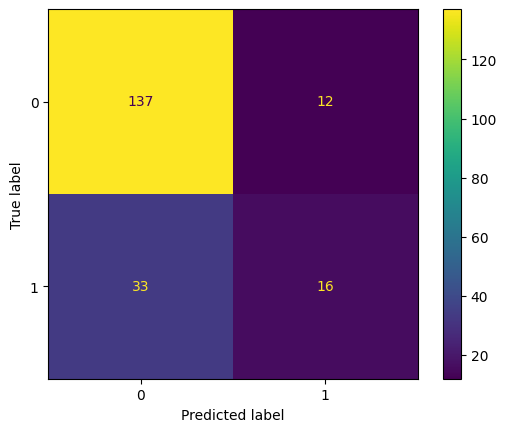

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score, roc_auc_score, ConfusionMatrixDisplay

# Fit the LogisticRegression with max iteration of 1000
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

# Predict the values for test data
y_pred = model.predict(X_test)

# Scores of the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)

print('Scores: ')
print(f'Accuracy: {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')
print(f'F1: {f1:.3f}')
print(f'ROC_AUC: {roc_auc:.3f}')

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print('\nConfusion Matrix:')
ConfusionMatrixDisplay(cm).plot()



In [ ]:
# Coefficients
for feature, coef_value in zip(X.columns, model.coef_[0]):
  print(f'{feature:>23}: {coef_value:.3f}')

                    age: -0.256
            distance_km: 0.231
                fee_inr: 0.442
              lead_days: 0.610
         prior_no_shows: 0.649
     reminder_sent_flag: -0.576
  booking_channel_Phone: 0.256
booking_channel_Walk-In: -0.155
   visit_type_Follow-up: -0.046


In [ ]:
import numpy as np

# Identify index of 'reminder_sent_flag' in our feature columns
reminder_idx = X.columns.get_loc('reminder_sent_flag')
coef_scaled = model.coef_[0][reminder_idx]

print(f"Scaled Coefficient for reminder_sent_flag: {coef_scaled:.3f}")
print(f"Scaled np.exp(coefficient): {np.exp(coef_scaled):.3f}")


std_dev = scaler.scale_[reminder_idx]

# Unscaled coefficient
coef_unscaled = coef_scaled / std_dev

print(f"Unscaled np.exp(coefficient / std_dev): {np.exp(coef_unscaled):.3f}")

Scaled Coefficient for reminder_sent_flag: -0.576
Scaled np.exp(coefficient): 0.562
Unscaled np.exp(coefficient / std_dev): 0.312


**Why they differ:**

These two numbers differ because the first one represents the odds ratio corresponding to a change of one standard deviation in the scaled reminder_sent_flag feature (moving from No (0) to std dev Yes (0.49) on the scaled version), whereas the second (unscaled) represents the odds ratio for a full unit change (moving from No 0 to Yes 1 on the original binary scale).

**Conclusion:**

In this model, holding all other features constant, an appointment where a reminder was sent is associated with approximately **0.312 times** the odds of being a no-show compared to an appointment where no reminder was sent.

## Task 3.3 — Decision tree and overfitting

Fit DecisionTreeClassifier(random_state=42) with no depth limit, and again with max_depth=3. For each, report training accuracy and test accuracy, and state in one sentence what the gap shows.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# DecisionTree Model without a specified depth
dtree_model = DecisionTreeClassifier()

dtree_model.fit(X_train, y_train)

print(f'Training Accuracy: {dtree_model.score(X_train, y_train)}')
print(f'Test Accuracy: {dtree_model.score(X_test, y_test):.3f}')

Training Accuracy: 1.0
Test Accuracy: 0.707


**DecisionTreeClassifier with no limit on depth**

The Training Accuracy being high and Testing accuracy being low indicates the model is Overfitting.

In [ ]:
# DecisionTree Model tree depth = 3
dtree_3d_model = DecisionTreeClassifier(max_depth=3)

dtree_3d_model.fit(X_train, y_train)

print(f'Training Accuracy: {dtree_3d_model.score(X_train, y_train):.3f}')
print(f'Test Accuracy: {dtree_3d_model.score(X_test, y_test):.3f}')

Training Accuracy: 0.818
Test Accuracy: 0.768


**DecisionTreeClassifier with tree depth = 3**

The Training Accuracy and Testing accuracy are relatively close to each other. This indicates the model is balanced. But the Testing Accuracy is still low and needs more improvement.

## Task 3.4 — Random forest and a comparison table

Fit RandomForestClassifier(n_estimators=100, random_state=42). Report accuracy, recall and ROC-AUC (use predict_proba(X_test)[:, 1] for AUC) and the top three rf.feature_importances_ (the attribute name is given because the course mentioned the idea only briefly). Then build a table with one row each for logistic regression, the depth-3 tree and the random forest (accuracy, recall, ROC-AUC) and say which model looks best and why; this table is for reporting — the formal choice is made in Task 3.5

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

rfc_model = RandomForestClassifier(n_estimators=100, random_state=42)

rfc_model.fit(X_train, y_train)

y_rfc_pred = rfc_model.predict(X_test)

# Scores of the model
rfc_accuracy = accuracy_score(y_test, y_rfc_pred)
rfc_recall = recall_score(y_test, y_rfc_pred)
rfc_roc_auc = roc_auc_score(y_test, y_rfc_pred)

print('Scores: ')
print(f'Accuracy: {rfc_accuracy:.3f}')
print(f'Recall: {rfc_recall:.3f}')
print(f'ROC_AUC: {rfc_roc_auc:.3f}')

print('\nTop 3 Features and their importance: ')

# Sort the importance and their feature name using X.columns in the descending order of importance
feature_imp = sorted(zip(X.columns, rfc_model.feature_importances_), key=lambda x: x[1], reverse=True)

# Top 3 Feature and their Importances
for feature, imp in feature_imp[:3]:
  print(f'{feature:>10} : {imp:.3f}')

Scores: 
Accuracy: 0.758
Recall: 0.327
ROC_AUC: 0.613

Top 3 Features and their importance: 
 lead_days : 0.233
       age : 0.220
   fee_inr : 0.159


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from tabulate import tabulate

# Compare the results of 3 models - LogisticRegression, DecisionTreeClassifier and RandomForestClassifier
models = {
        "LogisticRegression": LogisticRegression(max_iter=1000),
        "DecisionTree": DecisionTreeClassifier(max_depth=3),
        "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    }

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    accuracy = accuracy_score(y_test, preds)
    recall = recall_score(y_test, preds)
    roc_auc = roc_auc_score(y_test, preds)
    result = {}
    result['model'] = name
    result['accuracy'] = round(accuracy,3)
    result['recall'] = round(recall,3)
    result['roc_auc'] = round(roc_auc,3)

    results.append(result)

print(tabulate(results, headers="keys", tablefmt="grid"))

+--------------------+------------+----------+-----------+
| model              |   accuracy |   recall |   roc_auc |
+====================+============+==========+===========+
| LogisticRegression |      0.773 |    0.327 |     0.623 |
+--------------------+------------+----------+-----------+
| DecisionTree       |      0.768 |    0.286 |     0.606 |
+--------------------+------------+----------+-----------+
| RandomForest       |      0.758 |    0.327 |     0.613 |
+--------------------+------------+----------+-----------+


## Task 3.5 — Tune, choose the model and the threshold, then test once

(a) Run GridSearchCV(RandomForestClassifier(random_state=42), {"n_estimators": [100, 200], "max_depth": [3, 5, 8]}, cv=5, scoring="roc_auc") on the training set; print best_params_ and best_score_ (a cross-validated ROC-AUC).

(b) Choose the final model without touching the test set: compute the 5-fold cross-validated ROC-AUC on the training set for logistic regression, the depth-3 tree and the random forest — cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc").mean() — and compare them with the tuned forest's best_score_. For logistic regression, give cross_val_score the unscaled X_train together with the supplied pipeline below, so that the scaler is re-fitted on each fold's own training part (scaling the whole training set first would let each validation fold influence the scaler). The highest wins.

(c) Choose the threshold without touching the test set: get out-of-fold training probabilities for the winner with cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba")[:, 1] (for logistic regression use the pipeline and the unscaled X_train) and compare thresholds 0.5 and 0.35 on precision, recall, F1 and number flagged; pick the threshold with the higher F1 and say why recall matters here (a missed warning costs an empty slot, an extra call costs a minute).

(d) Fit the winner on the training set (the pipeline fits its own scaler) and evaluate it once on the test set at your chosen threshold: precision, recall, number flagged and ROC-AUC.

(e) Save test_risk_scores.csv with columns appointment_id, no_show, risk_prob, flag (1 if risk_prob ≥ your threshold) for every test row. (To get appointment_id, keep it aside before building X, or use X_test.index to look it up in the loaded DataFrame.) In one sentence, say how a clinic would really choose the threshold: by how many follow-up calls the front desk can make in an evening, against the cost of an empty slot.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 3.5a: Use GridSearchCV to calculate the best param and best score for
# RandomForestClassifier model
parameters = {
    "n_estimators": [100,200],
    "max_depth": [3,5,8]
    }

search_model = GridSearchCV(RandomForestClassifier(random_state=42),parameters,cv=5,scoring="roc_auc")

search_model.fit(X_train, y_train)


gridsearch_bestscore = round(search_model.best_score_,3)

print(f"Best Params: {search_model.best_params_}")
print(f"Best Score: {gridsearch_bestscore}")

Best Params: {'max_depth': 5, 'n_estimators': 200}
Best Score: 0.769


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# 3.5b: Using cross_val_score, compare the score of different models on the
# training data only.

# Read the cleaned data of appointments
appts_clean_df = pd.read_csv('/content/appointments_clean.csv')

data = appts_clean_df[['age','distance_km','fee_inr','lead_days','prior_no_shows','reminder_sent','booking_channel','visit_type']]

# Convert the Yes/No into 1/0
data['reminder_sent_flag'] = (data['reminder_sent'] == 'Yes').astype(int)

# Drop the duplicate column
data = data.drop(columns='reminder_sent')

# One-Hot encoding of non-numerical values
X = pd.get_dummies(data, drop_first=True ,dtype=int)

# Target
y = appts_clean_df['no_show']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)


# --- 1. Logistic Regression Pipeline (with unscaled X_train) ---
log_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(random_state=42))
])
lr_score = cross_val_score(log_reg_pipeline, X_train, y_train, cv=5, scoring="roc_auc").mean()

# --- 2. Depth-3 Decision Tree ---
tree_depth3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_score = cross_val_score(tree_depth3, X_train, y_train, cv=5, scoring="roc_auc").mean()

# --- 3. Standard Random Forest ---
rf_model = RandomForestClassifier(random_state=42)
rf_score = cross_val_score(rf_model, X_train, y_train, cv=5, scoring="roc_auc").mean()

# --- 4. Tuned Random Forest score  ---
tuned_rf_score = gridsearch_bestscore


# --- Comparison ---
scores = {
    "Logistic Regression (Pipeline)": lr_score,
    "Depth-3 Decision Tree": tree_score,
    "Standard Random Forest": rf_score,
    "Tuned Random Forest": tuned_rf_score
}

print("5-Fold Cross-Validated ROC-AUC Scores:")
for model_name, score in scores.items():
    print(f"  - {model_name}: {score:.3f}")

best_model_name = max(scores, key=scores.get)
print(f"\n******* Winning Model: {best_model_name} with an ROC-AUC of {scores[best_model_name]:.3f} *********")


5-Fold Cross-Validated ROC-AUC Scores:
  - Logistic Regression (Pipeline): 0.775
  - Depth-3 Decision Tree: 0.680
  - Standard Random Forest: 0.754
  - Tuned Random Forest: 0.769

******* Winning Model: Logistic Regression (Pipeline) with an ROC-AUC of 0.775 *********


In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# 3.5c: Using the cross_val_predict to find the best threshold on the
# Winning Model (Logistic Regression (pipeline)) from the previous section

# Get out-of-fold predicted probabilities for the positive class ([:, 1])
y_train_proba = cross_val_predict(log_reg_pipeline, X_train, y_train, cv=5, method="predict_proba")[:, 1]

thresholds = [0.5, 0.35]
evaluation_results = {}

print("Threshold Evaluation on Training Set (Out-of-Fold):\n" + "-"*50)

for thresh in thresholds:
    # Using threshold convert the probability to a Yes(1) or No(0)
    y_pred_thresh = (y_train_proba >= thresh).astype(int)

    prec = precision_score(y_train, y_pred_thresh, zero_division=0)
    rec = recall_score(y_train, y_pred_thresh, zero_division=0)
    f1 = f1_score(y_train, y_pred_thresh, zero_division=0)
    flagged = int(y_pred_thresh.sum())

    evaluation_results[thresh] = {
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "flagged": flagged
    }

    print(f"Threshold: {thresh}")
    print(f"  - Precision:   {prec:.3f}")
    print(f"  - Recall:      {rec:.3f}")
    print(f"  - F1-Score:    {f1:.3f}")
    print(f"  - Number Flagged: {flagged}\n")


# Find the threshold with the higher F1-score
best_threshold = max(thresholds, key=lambda t: evaluation_results[t]["f1"])
print(f"-> Selected Threshold (Higher F1): {best_threshold}")

Threshold Evaluation on Training Set (Out-of-Fold):
--------------------------------------------------
Threshold: 0.5
  - Precision:   0.563
  - Recall:      0.237
  - F1-Score:    0.333
  - Number Flagged: 71

Threshold: 0.35
  - Precision:   0.484
  - Recall:      0.444
  - F1-Score:    0.463
  - Number Flagged: 155

-> Selected Threshold (Higher F1): 0.35


**Why Recall Matters Here (The Cost Trade-Off)**

In this specific scenario, recall matters significantly more than precision because of the cost/impact difference for the 2 thresholds :

- The cost of a false negative (missed warning): Leaves an empty slot. An empty slot represents uncaptured value or a lost opportunity, which carries a much higher penalty.

- The cost of a false positive (extra call): Costs only a minute of time.

Lowering the threshold from 0.5 to 0.35 helps to brings more customers into the no-show category, catching more true positives (increasing recall) at the expense of a few extra false positives. Since an extra call is cheap (just a minute), the boost in recall heavily outweighs the slight drop in precision, resulting in a superior F1-score.

In [ ]:
#  3.5d: Fit the Logistic Regression (Pipeline) to the optimum threshold to the Test data
#  and predict the outcomes
from sklearn.metrics import precision_score, recall_score, f1_score


optimum_threshold = 0.35

log_reg_pipeline.fit(X_train, y_train)
y_pred_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

# Using threshold convert the probability to a Yes(1) or No(0)
y_pred = (y_pred_proba >= optimum_threshold).astype(int)


prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Precision:   {prec:.3f}")
print(f"Recall:      {rec:.3f}")
print(f"F1-Score:    {f1:.3f}")

Precision:   0.562
Recall:      0.551
F1-Score:    0.557


In [ ]:
# 3.5e: Save test_risk_scores.csv with columns appointment_id, no_show, risk_prob, flag
# (1 if risk_prob >= threshold) for every test row.
import pandas as pd

test_original = appts_clean_df.loc[X_test.index]

test_risk_df = pd.DataFrame({
    'appointment_id': test_original['appointment_id'],
    'no_show': y_test,
    'risk_prob': y_pred_proba,
    'flag': y_pred
})

test_risk_df.to_csv('test_risk_scores.csv', index=False)
print("Saved test_risk_scores.csv successfully.")

# Clinic decision threshold explanation:
# Ultimately, a clinic would choose the operational threshold by balancing how
# many follow-up calls the front desk has the capacity to make in an evening
# against the potential financial loss and resource cost of leaving a clinic
# slot empty.

Saved test_risk_scores.csv successfully.


In [ ]:
calls_made = int(y_pred.sum())

print(f'Number off calls madee: {calls_made}')

NUmber off calls madee: 48
